In [1]:
# ============================
# STEP 1 : Import Libraries
# ============================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Plot style
sns.set_style("whitegrid")

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
# ============================
# STEP 2 : Load Dataset
# ============================

import pandas as pd

# Load the dataset from Colab
df = pd.read_csv("/content/Airline - Sheet1.csv")

# First 5 rows
df.head()

,Flight Number,Airline,Origin,Destination,Scheduled Departure,Actual Departure,Departure Delay (mins),Delay Reason,Turnaround Time (mins),Flight Status
0,6E-2073,IndiGo,COK,MAA,06:50:00,06:50:00,0,On-Time / Routine,46,On-Time
1,6E-2146,IndiGo,PNQ,CCU,07:45:00,07:47:00,2,On-Time / Routine,43,On-Time
2,6E-2219,IndiGo,HYD,CCU,08:40:00,08:44:00,4,On-Time / Routine,40,On-Time
3,UK-822,Vistara,DEL,HYD,10:30:00,10:37:00,7,On-Time / Routine,54,On-Time
4,QP-1285,Akasa Air,GOI,BLR,11:25:00,12:38:00,73,Late Inbound Aircraft,103,Delayed


In [4]:
# Shape of the dataset
print(df.shape)

# Column names
print(df.columns)

# Dataset information
df.info()

(1500, 10)
Index(['Flight Number', 'Airline', 'Origin', 'Destination',
       'Scheduled Departure', 'Actual Departure', 'Departure Delay (mins)',
       'Delay Reason', 'Turnaround Time (mins)', 'Flight Status'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Flight Number           1500 non-null   object
 1   Airline                 1500 non-null   object
 2   Origin                  1500 non-null   object
 3   Destination             1500 non-null   object
 4   Scheduled Departure     1500 non-null   object
 5   Actual Departure        1500 non-null   object
 6   Departure Delay (mins)  1500 non-null   int64 
 7   Delay Reason            1500 non-null   object
 8   Turnaround Time (mins)  1500 non-null   int64 
 9   Flight Status           1500 non-null   object
dtypes: int64(2), object(8)
memor

In [5]:
# ============================
# STEP 3 : Basic Information
# ============================

print("Shape of Dataset:", df.shape)

print("\nColumn Names")
print(df.columns)

print("\nDataset Information")
df.info()

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

print("\nStatistical Summary")
df.describe(include="all")

Shape of Dataset: (1500, 10)

Column Names
Index(['Flight Number', 'Airline', 'Origin', 'Destination',
       'Scheduled Departure', 'Actual Departure', 'Departure Delay (mins)',
       'Delay Reason', 'Turnaround Time (mins)', 'Flight Status'],
      dtype='object')

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Flight Number           1500 non-null   object
 1   Airline                 1500 non-null   object
 2   Origin                  1500 non-null   object
 3   Destination             1500 non-null   object
 4   Scheduled Departure     1500 non-null   object
 5   Actual Departure        1500 non-null   object
 6   Departure Delay (mins)  1500 non-null   int64 
 7   Delay Reason            1500 non-null   object
 8   Turnaround Time (mins)  1500 non-null   int64 
 9   Flight Status           150

,Flight Number,Airline,Origin,Destination,Scheduled Departure,Actual Departure,Departure Delay (mins),Delay Reason,Turnaround Time (mins),Flight Status
count,1500,1500,1500,1500,1500,1500,1500.000000,1500,1500.000000,1500
unique,764,6,10,10,144,589,NaN,5,NaN,3
top,IX-815,IndiGo,COK,BLR,08:40:00,13:47:00,NaN,On-Time / Routine,NaN,On-Time
freq,5,825,150,151,13,8,NaN,1034,NaN,809
mean,NaN,NaN,NaN,NaN,NaN,NaN,18.357333,NaN,54.152000,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,27.658169,NaN,18.927645,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,-5.000000,NaN,35.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,40.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,46.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,36.000000,NaN,62.000000,NaN


In [7]:
# ============================
# STEP 4 : Data Cleaning
# ============================

# Remove duplicates
df = df.drop_duplicates()

# Remove missing values
df = df.dropna()

# Convert time columns into datetime format
df["Scheduled Departure"] = pd.to_datetime(
    df["Scheduled Departure"],
    format="%H:%M:%S"
)

df["Actual Departure"] = pd.to_datetime(
    df["Actual Departure"],
    format="%H:%M:%S"
)

# Extract departure hour
df["Departure Hour"] = df["Scheduled Departure"].dt.hour

# Create Day Period
def period(hour):
    if hour < 6:
        return "Night"
    elif hour < 12:
        return "Morning"
    elif hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df["Day Period"] = df["Departure Hour"].apply(period)

print("Cleaning Completed!")

df.head()

Cleaning Completed!


,Flight Number,Airline,Origin,Destination,Scheduled Departure,Actual Departure,Departure Delay (mins),Delay Reason,Turnaround Time (mins),Flight Status,Departure Hour,Day Period
0,6E-2073,IndiGo,COK,MAA,1900-01-01 06:50:00,1900-01-01 06:50:00,0,On-Time / Routine,46,On-Time,6,Morning
1,6E-2146,IndiGo,PNQ,CCU,1900-01-01 07:45:00,1900-01-01 07:47:00,2,On-Time / Routine,43,On-Time,7,Morning
2,6E-2219,IndiGo,HYD,CCU,1900-01-01 08:40:00,1900-01-01 08:44:00,4,On-Time / Routine,40,On-Time,8,Morning
3,UK-822,Vistara,DEL,HYD,1900-01-01 10:30:00,1900-01-01 10:37:00,7,On-Time / Routine,54,On-Time,10,Morning
4,QP-1285,Akasa Air,GOI,BLR,1900-01-01 11:25:00,1900-01-01 12:38:00,73,Late Inbound Aircraft,103,Delayed,11,Morning


In [8]:
# ============================
# STEP 5 : Descriptive Statistics
# ============================

print("Average Delay:", df["Departure Delay (mins)"].mean())

print("Maximum Delay:", df["Departure Delay (mins)"].max())

print("Minimum Delay:", df["Departure Delay (mins)"].min())

print("Average Turnaround Time:", df["Turnaround Time (mins)"].mean())

print("\nFlight Status Count")
print(df["Flight Status"].value_counts())

print("\nDelay Reason Count")
print(df["Delay Reason"].value_counts())

Average Delay: 18.357333333333333
Maximum Delay: 104
Minimum Delay: -5
Average Turnaround Time: 54.152

Flight Status Count
Flight Status
On-Time    809
Delayed    466
Early      225
Name: count, dtype: int64

Delay Reason Count
Delay Reason
On-Time / Routine          1034
Late Inbound Aircraft       303
Ground Operations            73
Technical / Maintenance      71
Air Traffic Control          19
Name: count, dtype: int64


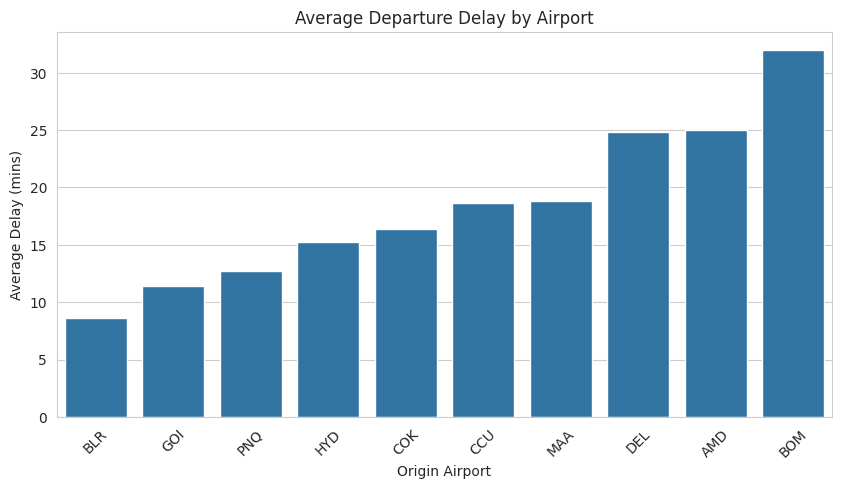

In [9]:
# ============================
# Visualization 1
# Delay Rate by Airport
# ============================

airport_delay = df.groupby("Origin")["Departure Delay (mins)"].mean().sort_values()

plt.figure(figsize=(10,5))
sns.barplot(x=airport_delay.index, y=airport_delay.values)

plt.title("Average Departure Delay by Airport")
plt.xlabel("Origin Airport")
plt.ylabel("Average Delay (mins)")
plt.xticks(rotation=45)

plt.show()

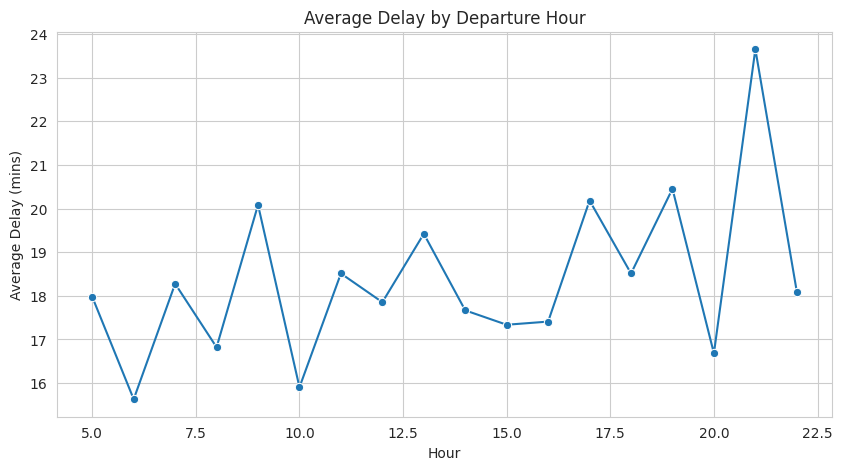

In [10]:
# ============================
# Visualization 2
# Delay by Departure Hour
# ============================

hour_delay = df.groupby("Departure Hour")["Departure Delay (mins)"].mean()

plt.figure(figsize=(10,5))

sns.lineplot(
    x=hour_delay.index,
    y=hour_delay.values,
    marker="o"
)

plt.title("Average Delay by Departure Hour")
plt.xlabel("Hour")
plt.ylabel("Average Delay (mins)")

plt.show()

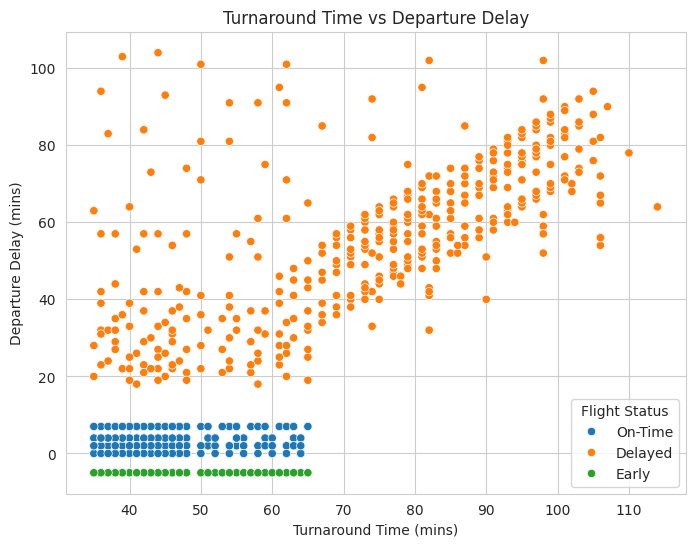

In [11]:
# ============================
# Visualization 3
# Turnaround Time vs Delay
# ============================

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Turnaround Time (mins)",
    y="Departure Delay (mins)",
    hue="Flight Status"
)

plt.title("Turnaround Time vs Departure Delay")

plt.show()

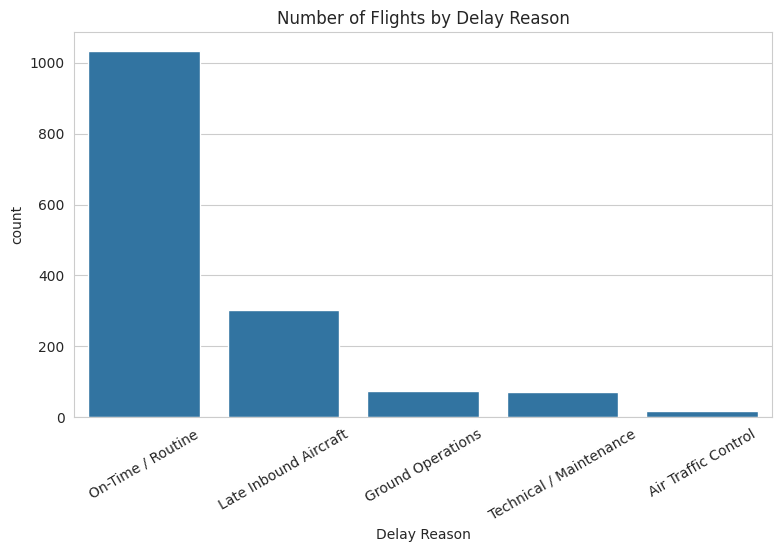

In [12]:
# ============================
# Visualization 4
# Delay Reason
# ============================

plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x="Delay Reason",
    order=df["Delay Reason"].value_counts().index
)

plt.title("Number of Flights by Delay Reason")
plt.xticks(rotation=30)

plt.show()

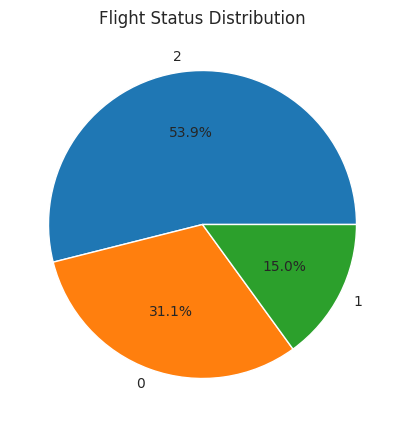

In [16]:
# Flight Status Distribution

plt.figure(figsize=(5,5))

df["Flight Status"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Flight Status Distribution")

plt.show()

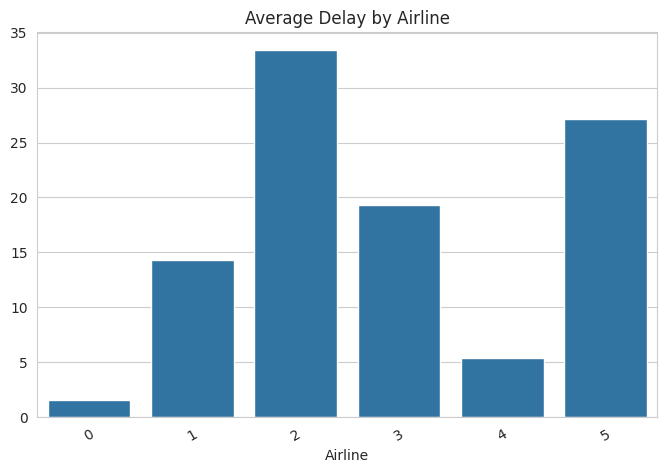

In [17]:
# Average Delay by Airline

airline_delay = (
    df.groupby("Airline")["Departure Delay (mins)"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=airline_delay.index,
    y=airline_delay.values
)

plt.title("Average Delay by Airline")
plt.xticks(rotation=30)

plt.show()

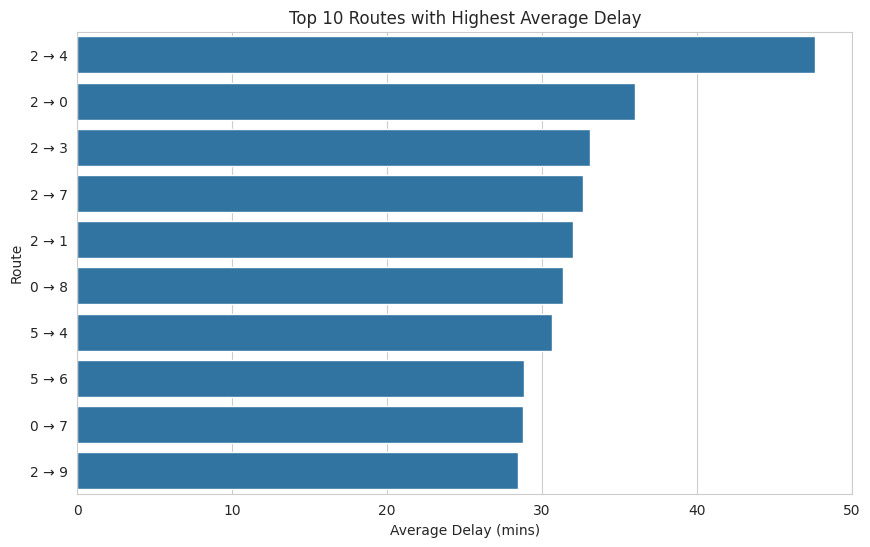

In [19]:
# ============================
# Route Delay Analysis
# ============================

df["Route"] = df["Origin"].astype(str) + " → " + df["Destination"].astype(str)

route_delay = (
    df.groupby("Route")["Departure Delay (mins)"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=route_delay.values,
    y=route_delay.index
)

plt.title("Top 10 Routes with Highest Average Delay")
plt.xlabel("Average Delay (mins)")

plt.show()

In [13]:
# ============================
# STEP 13 : Encoding
# ============================

encoder = LabelEncoder()

categorical_columns = [
    "Flight Number",
    "Airline",
    "Origin",
    "Destination",
    "Delay Reason",
    "Flight Status",
    "Day Period"
]

for column in categorical_columns:
    df[column] = encoder.fit_transform(df[column])

print("Encoding Completed!")

df.head()

Encoding Completed!


,Flight Number,Airline,Origin,Destination,Scheduled Departure,Actual Departure,Departure Delay (mins),Delay Reason,Turnaround Time (mins),Flight Status,Departure Hour,Day Period
0,40,3,4,8,1900-01-01 06:50:00,1900-01-01 06:50:00,0,3,46,2,6,2
1,81,3,9,3,1900-01-01 07:45:00,1900-01-01 07:47:00,2,3,43,2,7,2
2,121,3,7,3,1900-01-01 08:40:00,1900-01-01 08:44:00,4,3,40,2,8,2
3,630,5,5,7,1900-01-01 10:30:00,1900-01-01 10:37:00,7,3,54,2,10,2
4,542,2,6,1,1900-01-01 11:25:00,1900-01-01 12:38:00,73,2,103,0,11,2


In [14]:
# ============================
# STEP 14 : Features and Target
# ============================

X = df[[
    "Flight Number",
    "Airline",
    "Origin",
    "Destination",
    "Departure Delay (mins)",
    "Delay Reason",
    "Turnaround Time (mins)",
    "Departure Hour",
    "Day Period"
]]

y = df["Flight Status"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1500, 9)
Target Shape: (1500,)


In [15]:
# ============================
# STEP 15 : Split Dataset
# ============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", X_train.shape)
print("Testing Samples:", X_test.shape)

Training Samples: (1200, 9)
Testing Samples: (300, 9)


In [21]:
# ============================
# STEP 16 : Random Forest Model
# ============================

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [22]:
# ============================
# STEP 17 : Prediction
# ============================

y_pred = model.predict(X_test)

print("Prediction Completed!")

Prediction Completed!


In [24]:
# ============================
# STEP 18 : Evaluation Metrics
# ============================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, average='weighted')

recall = recall_score(y_test, y_pred, average='weighted')

f1 = f1_score(y_test, y_pred, average='weighted')

print("Accuracy :", accuracy)

print("Precision:", precision)

print("Recall   :", recall)

print("F1 Score :", f1)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


In [25]:
# Classification Report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        98
           1       1.00      1.00      1.00        46
           2       1.00      1.00      1.00       156

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



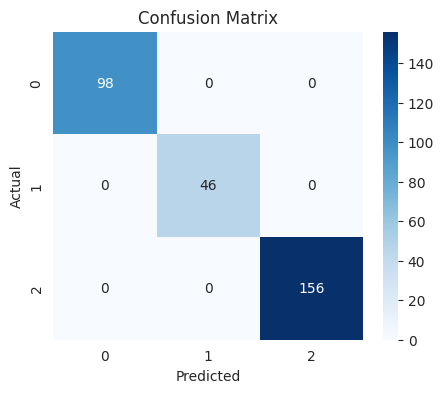

In [26]:
# ============================
# Confusion Matrix
# ============================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

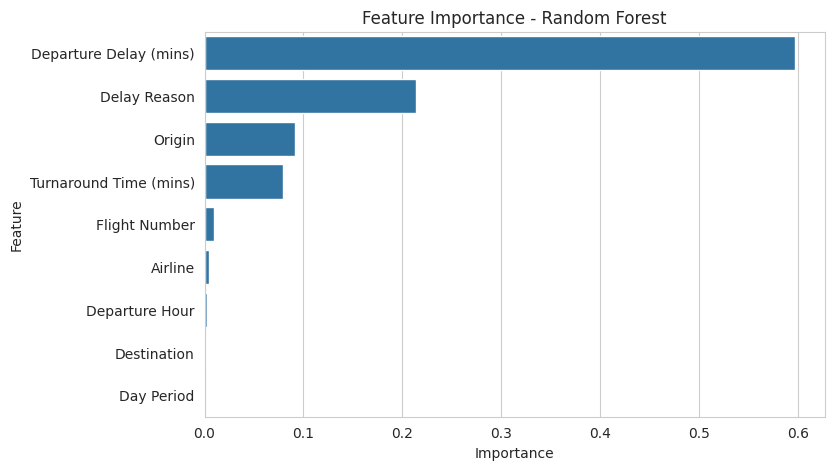

,Feature,Importance
4,Departure Delay (mins),0.597245
5,Delay Reason,0.213810
2,Origin,0.091737
6,Turnaround Time (mins),0.078979
0,Flight Number,0.009822
1,Airline,0.004468
7,Departure Hour,0.002226
3,Destination,0.001310
8,Day Period,0.000402


In [28]:
# ============================
# Feature Importance
# ============================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")

plt.show()

importance

In [29]:
# ============================
# Final Project Insights
# ============================

print("1. Airport with Highest Average Delay:")
print(df.groupby("Origin")["Departure Delay (mins)"].mean().sort_values(ascending=False).head(1))

print("\n2. Hour with Highest Average Delay:")
print(df.groupby("Departure Hour")["Departure Delay (mins)"].mean().sort_values(ascending=False).head(1))

print("\n3. Airline with Highest Average Delay:")
print(df.groupby("Airline")["Departure Delay (mins)"].mean().sort_values(ascending=False).head(1))

print("\n4. Delay Reason Counts:")
print(df.groupby("Delay Reason")["Departure Delay (mins)"].count())

print("\n5. Average Delay by Turnaround Time:")
print(df["Turnaround Time (mins)"].corr(df["Departure Delay (mins)"]))

print("\n6. Top Delayed Routes:")
print(df.groupby("Route")["Departure Delay (mins)"].mean().sort_values(ascending=False).head(5))

1. Airport with Highest Average Delay:
Origin
2    31.946667
Name: Departure Delay (mins), dtype: float64

2. Hour with Highest Average Delay:
Departure Hour
21    23.650602
Name: Departure Delay (mins), dtype: float64

3. Airline with Highest Average Delay:
Airline
2    33.380952
Name: Departure Delay (mins), dtype: float64

4. Delay Reason Counts:
Delay Reason
0      19
1      73
2     303
3    1034
4      71
Name: Departure Delay (mins), dtype: int64

5. Average Delay by Turnaround Time:
0.7609695569642084

6. Top Delayed Routes:
Route
2 → 4    47.647059
2 → 0    36.000000
2 → 3    33.125000
2 → 7    32.647059
2 → 1    32.000000
Name: Departure Delay (mins), dtype: float64
